#**Details:**
**Name:** Siddhesh Abasaheb Mane

**PRN:** 202401040187

**Batch:** A2

**Roll No.:** 46

---

### Objective

To implement and analyse ensemble learning techniques including Stacking, AdaBoost, and Voting for Chronic Kidney Disease classification, and compare their performance with the individual base machine-learning classifiers using appropriate classification metrics.

## 1. Introduction

Ensemble learning is a machine-learning approach in which multiple models are combined to produce a stronger predictive model. Instead of relying on a single classifier, ensemble methods combine the strengths of different learners to improve classification performance and generalisation.

In this practical, three ensemble learning techniques are implemented: **Stacking, AdaBoost, and Voting**. Their performance is compared with the individual base classifiers used to construct the ensembles.

The experiment is performed on the UCI Chronic Kidney Disease (CKD) dataset. The dataset contains numerical clinical measurements and categorical medical indicators. Preprocessing is performed manually and explicitly, including missing-value imputation, categorical encoding, age-group creation, log transformation, and feature scaling.

The selected base classifiers are Logistic Regression, Decision Tree, and K-Nearest Neighbours (KNN).

In [ ]:
# Import required libraries

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# UCI dataset access
!pip -q install ucimlrepo
from ucimlrepo import fetch_ucirepo

# Scikit-learn: data splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Base classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Ensemble classifiers
from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)

print("All libraries imported successfully.")

All libraries imported successfully.


## 2. Dataset Selection

The **Chronic Kidney Disease dataset** from the UCI Machine Learning Repository is selected for this practical. It contains 400 patient records, 24 predictor features, and one target variable. The target indicates whether the record belongs to the CKD or Not CKD class.

The features include patient age, blood pressure, urine measurements, blood-test results, and medical indicators such as hypertension and diabetes.

The task is a **binary classification problem**:
- `ckd` = 1
- `notckd` = 0

The dataset contains missing values and a mixture of numerical and categorical attributes. Therefore, data cleaning and feature engineering are carried out before model training.

**Dataset source:** UCI Machine Learning Repository – Chronic Kidney Disease, ID 336: https://archive.ics.uci.edu/dataset/336/chronic+kidney+disease

In [ ]:
# Load the CKD dataset from UCI

ckd = fetch_ucirepo(id=336)

X_raw = ckd.data.features.copy()
y_raw = ckd.data.targets.copy()

df = pd.concat([X_raw, y_raw], axis=1)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully.
Dataset shape: (400, 25)
Number of records: 400
Number of columns: 25


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


In [ ]:
# Display basic dataset information

print("Column names:")
print(df.columns.tolist())

print("\\nData types:")
print(df.dtypes)

print("\\nTarget class counts before cleaning:")
display(y_raw.iloc[:, 0].value_counts(dropna=False))

Column names:
['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']
\nData types:
age      float64
bp       float64
sg       float64
al       float64
su       float64
rbc       object
pc        object
pcc       object
ba        object
bgr      float64
bu       float64
sc       float64
sod      float64
pot      float64
hemo     float64
pcv      float64
wbcc     float64
rbcc     float64
htn       object
dm        object
cad       object
appet     object
pe        object
ane       object
class     object
dtype: object
\nTarget class counts before cleaning:


,count
class,
ckd,248
notckd,150
ckd\t,2


In [ ]:
# Display target class distribution after cleaning labels

target_col = y_raw.columns[0]

target_clean = (
    y_raw[target_col]
    .astype("string")
    .str.replace("\\t", "", regex=False)
    .str.strip()
    .str.lower()
)

y_all = target_clean.map({"notckd": 0, "ckd": 1})
valid_target = y_all.notna()

X = X_raw.loc[valid_target].copy().reset_index(drop=True)
y = y_all.loc[valid_target].astype(int).reset_index(drop=True)

print("Target labels: 0 = Not CKD, 1 = CKD")
display(y.value_counts().rename(index={0: "Not CKD", 1: "CKD"}))

Target labels: 0 = Not CKD, 1 = CKD


,count
class,
CKD,250
Not CKD,150


In [ ]:
# Display numerical feature statistics

numeric_features = [
    "age", "bp", "sg", "al", "su", "bgr", "bu", "sc",
    "sod", "pot", "hemo", "pcv", "wbcc", "rbcc"
]
numeric_features = [col for col in numeric_features if col in X.columns]

for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

display(X[numeric_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,391.0,51.483376,17.169714,2.000,42.00,55.00,64.50,90.000
bp,388.0,76.469072,13.683637,50.000,70.00,80.00,80.00,180.000
sg,353.0,1.017408,0.005717,1.005,1.01,1.02,1.02,1.025
al,354.0,1.016949,1.352679,0.000,0.00,0.00,2.00,5.000
su,351.0,0.450142,1.099191,0.000,0.00,0.00,0.00,5.000
bgr,356.0,148.036517,79.281714,22.000,99.00,121.00,163.00,490.000
bu,381.0,57.425722,50.503006,1.500,27.00,42.00,66.00,391.000
sc,383.0,3.072454,5.741126,0.400,0.90,1.30,2.80,76.000
sod,313.0,137.528754,10.408752,4.500,135.00,138.00,142.00,163.000
pot,312.0,4.627244,3.193904,2.500,3.80,4.40,4.90,47.000


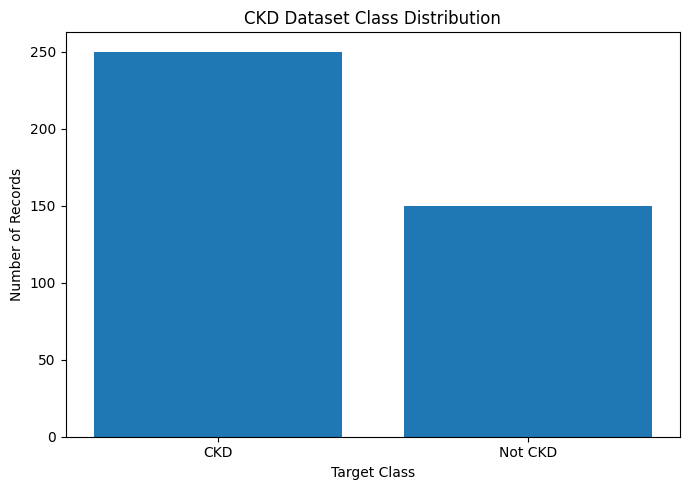

Class percentages:


,count
class,
CKD,62.5
Not CKD,37.5


In [ ]:
# Visualize target class distribution

target_counts = y.map({0: "Not CKD", 1: "CKD"}).value_counts()

plt.figure(figsize=(7, 5))
plt.bar(target_counts.index, target_counts.values)
plt.title("CKD Dataset Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

print("Class percentages:")
display((target_counts / target_counts.sum() * 100).round(2))

## 3. Data Preprocessing

The CKD dataset contains missing observations, numerical measurements with different scales, and categorical features stored as text. The following manual preprocessing operations are performed:

1. **Missing-value handling:** Median imputation for numerical features and mode imputation for categorical features.
2. **Categorical encoding:** Binary categories are explicitly mapped to 0 and 1.
3. **Feature engineering:** Age is grouped into age categories, and a log-transformed BGR feature is created.
4. **Feature scaling:** StandardScaler is applied to numerical features. Min-Max scaling is also demonstrated separately.

The train-test split is performed before model-related imputation and scaling. Imputation and scaling parameters are learned from training data only and then applied to the test data to avoid data leakage.

Since this is tabular clinical data, image resizing and image augmentation are not applicable.

In [ ]:
# Identify numerical and categorical feature names

categorical_features = [
    col for col in X.columns if col not in numeric_features
]

# Clean categorical text: remove tab characters, spaces and convert to lowercase
for col in categorical_features:
    X[col] = (
        X[col].astype("string")
        .str.replace("\\t", "", regex=False)
        .str.strip()
        .str.lower()
        .replace({"": pd.NA, "?": pd.NA, "nan": pd.NA})
    )

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']
Categorical features: ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


In [ ]:
# Check missing values in every feature

missing_summary = pd.DataFrame({
    "Missing Count": X.isnull().sum(),
    "Missing Percentage": (X.isnull().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)

display(missing_summary)

,Missing Count,Missing Percentage
rbc,152,38.00
rbcc,131,32.75
wbcc,106,26.50
pot,88,22.00
sod,87,21.75
pcv,71,17.75
pc,65,16.25
hemo,52,13.00
su,49,12.25
sg,47,11.75


In [ ]:
# Demonstrate mean, median and mode imputation using a small example

demo = pd.DataFrame({
    "age": [25, 30, 35, np.nan, 40],
    "serum_creatinine": [0.8, 1.0, 1.2, np.nan, 10.0],
    "hypertension": ["no", "no", "yes", np.nan, "yes"]
})

print("Original demonstration data:")
display(demo)

demo_mean = demo.copy()
demo_median = demo.copy()
demo_mode = demo.copy()

for col in ["age", "serum_creatinine"]:
    demo_mean[col] = demo_mean[col].fillna(demo_mean[col].mean())
    demo_median[col] = demo_median[col].fillna(demo_median[col].median())

demo_mode["hypertension"] = demo_mode["hypertension"].fillna(
    demo_mode["hypertension"].mode()[0]
)

print("Mean imputation:")
display(demo_mean)

print("Median imputation:")
display(demo_median)

print("Mode imputation:")
display(demo_mode)

Original demonstration data:


,age,serum_creatinine,hypertension
0,25.0,0.8,no
1,30.0,1.0,no
2,35.0,1.2,yes
3,NaN,NaN,NaN
4,40.0,10.0,yes


Mean imputation:


,age,serum_creatinine,hypertension
0,25.0,0.80,no
1,30.0,1.00,no
2,35.0,1.20,yes
3,32.5,3.25,NaN
4,40.0,10.00,yes


Median imputation:


,age,serum_creatinine,hypertension
0,25.0,0.8,no
1,30.0,1.0,no
2,35.0,1.2,yes
3,32.5,1.1,NaN
4,40.0,10.0,yes


Mode imputation:


,age,serum_creatinine,hypertension
0,25.0,0.8,no
1,30.0,1.0,no
2,35.0,1.2,yes
3,NaN,NaN,no
4,40.0,10.0,yes


In [ ]:
# Split data into training and testing subsets

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (320, 24)
Testing data: (80, 24)
Training labels: (320,)
Testing labels: (80,)


In [ ]:
# Perform median imputation on numerical columns
# Medians are calculated using training data only.

train_medians = X_train[numeric_features].median()

X_train[numeric_features] = X_train[numeric_features].fillna(train_medians)
X_test[numeric_features] = X_test[numeric_features].fillna(train_medians)

print("Missing numerical values in training data:",
      X_train[numeric_features].isnull().sum().sum())

print("Missing numerical values in testing data:",
      X_test[numeric_features].isnull().sum().sum())

Missing numerical values in training data: 0
Missing numerical values in testing data: 0


In [ ]:
# Perform mode imputation on categorical columns
# Modes are calculated using training data only.

train_modes = {}

for col in categorical_features:
    mode_values = X_train[col].mode(dropna=True)
    fill_value = mode_values.iloc[0] if not mode_values.empty else "missing"

    train_modes[col] = fill_value

    X_train[col] = X_train[col].fillna(fill_value)
    X_test[col] = X_test[col].fillna(fill_value)

print("Missing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

Missing values in training data: 0
Missing values in testing data: 0


In [ ]:
# Encode binary categorical features manually

binary_mappings = {
    "rbc": {"normal": 0, "abnormal": 1},
    "pc": {"normal": 0, "abnormal": 1},
    "pcc": {"notpresent": 0, "present": 1},
    "ba": {"notpresent": 0, "present": 1},
    "htn": {"no": 0, "yes": 1},
    "dm": {"no": 0, "yes": 1},
    "cad": {"no": 0, "yes": 1},
    "appet": {"poor": 0, "good": 1},
    "pe": {"no": 0, "yes": 1},
    "ane": {"no": 0, "yes": 1}
}

binary_mappings = {
    col: mapping for col, mapping in binary_mappings.items()
    if col in X_train.columns
}
binary_features = list(binary_mappings.keys())

for col, mapping in binary_mappings.items():
    X_train[col] = X_train[col].map(mapping)
    X_test[col] = X_test[col].map(mapping)

print("Remaining missing encoded values in train:",
      X_train[binary_features].isnull().sum().sum())

print("Remaining missing encoded values in test:",
      X_test[binary_features].isnull().sum().sum())

display(X_train[binary_features].head())

Remaining missing encoded values in train: 0
Remaining missing encoded values in test: 0


,rbc,pc,pcc,ba,htn,dm,cad,appet,pe,ane
108,0,1,0,0,0,0,0,1,0,0
210,0,0,0,0,1,1,1,1,0,1
137,0,1,1,0,1,1,0,1,0,0
148,0,0,0,0,1,0,0,0,0,0
246,1,0,1,0,1,0,1,1,0,1


In [ ]:
# Create age groups using binning

age_bins = [0, 18, 35, 55, 100]
age_labels = ["Young", "Young Adult", "Middle-Aged", "Older Adult"]

X_train["age_group"] = pd.cut(
    X_train["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

X_test["age_group"] = pd.cut(
    X_test["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

print("Age group distribution:")
display(X_train["age_group"].value_counts().sort_index())

# Convert age groups into dummy variables
train_age_dummies = pd.get_dummies(
    X_train["age_group"], prefix="age_group", dtype=int
)

test_age_dummies = pd.get_dummies(
    X_test["age_group"], prefix="age_group", dtype=int
)

test_age_dummies = test_age_dummies.reindex(
    columns=train_age_dummies.columns,
    fill_value=0
)

Age group distribution:


,count
age_group,
Young,15
Young Adult,45
Middle-Aged,118
Older Adult,142


In [ ]:
# Apply log1p transformation to Blood Glucose Random (BGR)

X_train["bgr_log"] = np.log1p(X_train["bgr"])
X_test["bgr_log"] = np.log1p(X_test["bgr"])

print("Original and transformed BGR values:")
display(X_train[["bgr", "bgr_log"]].head())

print("BGR skewness before transformation:", X_train["bgr"].skew())
print("BGR skewness after transformation:", X_train["bgr_log"].skew())

Original and transformed BGR values:


,bgr,bgr_log
108,107.0,4.682131
210,255.0,5.545177
137,268.0,5.594711
148,171.0,5.147494
246,106.0,4.672829


BGR skewness before transformation: 2.4084621958442374
BGR skewness after transformation: 0.9210283851368605


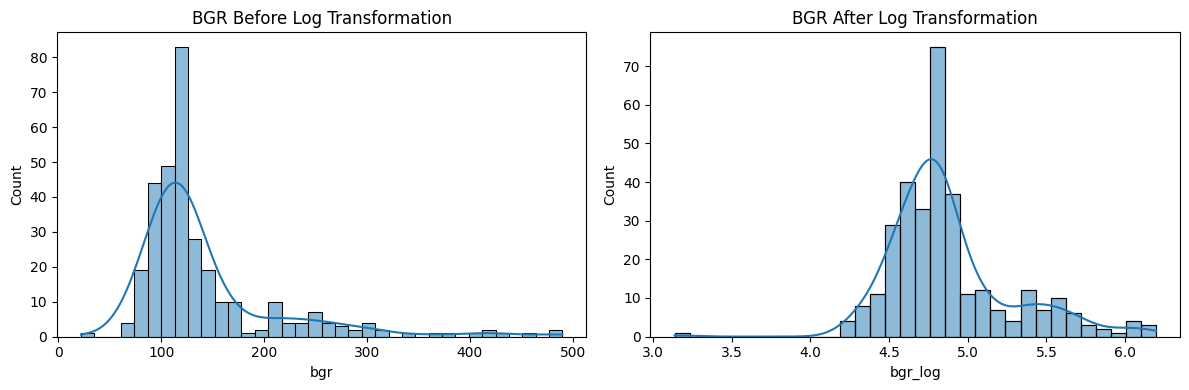

In [ ]:
# Visualize BGR before and after log transformation

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(X_train["bgr"], kde=True, ax=axes[0])
axes[0].set_title("BGR Before Log Transformation")

sns.histplot(X_train["bgr_log"], kde=True, ax=axes[1])
axes[1].set_title("BGR After Log Transformation")

plt.tight_layout()
plt.show()

In [ ]:
# Standardize numerical features using StandardScaler

scale_features = numeric_features + ["bgr_log"]

scaler = StandardScaler()

X_train_scaled_numeric = pd.DataFrame(
    scaler.fit_transform(X_train[scale_features]),
    columns=scale_features,
    index=X_train.index
)

X_test_scaled_numeric = pd.DataFrame(
    scaler.transform(X_test[scale_features]),
    columns=scale_features,
    index=X_test.index
)

print("Feature standardization completed successfully.")

Feature standardization completed successfully.


In [ ]:
# Combine scaled numerical, binary encoded and age-group features

X_train_final = pd.concat([
    X_train_scaled_numeric,
    X_train[binary_features].astype(int),
    train_age_dummies
], axis=1)

X_test_final = pd.concat([
    X_test_scaled_numeric,
    X_test[binary_features].astype(int),
    test_age_dummies
], axis=1)

# Ensure that training and testing data have identical feature columns
X_test_final = X_test_final.reindex(
    columns=X_train_final.columns,
    fill_value=0
)

print("Final training features:", X_train_final.shape)
print("Final testing features:", X_test_final.shape)
print("Missing values in training data:", X_train_final.isnull().sum().sum())
print("Missing values in testing data:", X_test_final.isnull().sum().sum())

Final training features: (320, 29)
Final testing features: (80, 29)
Missing values in training data: 0
Missing values in testing data: 0


## 4. Base Machine Learning Classifiers

Before implementing the ensemble methods, three different classification algorithms are trained individually. These models are selected from different learning approaches so that their predictions can provide useful diversity for the ensemble methods.

The selected base classifiers are:

1. **Logistic Regression** – a linear classification model.
2. **Decision Tree** – a nonlinear, rule-based classifier.
3. **K-Nearest Neighbours (KNN)** – a distance-based classifier.

Their individual performance is measured and later compared with the Stacking, AdaBoost, and Voting ensembles.

The CKD class (`1`) is treated as the positive class. Precision, recall, and F1-score are therefore calculated for CKD rather than as weighted averages across both classes.

In [ ]:
# Initialize the base classifiers

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

decision_tree_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=3,
    random_state=42
)

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

print("Base classifiers initialized successfully.")

Base classifiers initialized successfully.


In [ ]:
# Train the three base classifiers

print("Training Logistic Regression...")
logistic_model.fit(X_train_final, y_train)

print("Training Decision Tree...")
decision_tree_model.fit(X_train_final, y_train)

print("Training KNN...")
knn_model.fit(X_train_final, y_train)

print("\\nAll base classifiers trained successfully.")

Training Logistic Regression...
Training Decision Tree...
Training KNN...
\nAll base classifiers trained successfully.


In [ ]:
# Generate predictions for the test set

y_pred_logistic = logistic_model.predict(X_test_final)
y_pred_tree = decision_tree_model.predict(X_test_final)
y_pred_knn = knn_model.predict(X_test_final)

print("Predictions generated successfully.")

Predictions generated successfully.


In [ ]:
# Function to evaluate classification models

def evaluate_model(model_name, y_true, y_pred, y_prob):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Log Loss": log_loss(y_true, y_prob, labels=[0, 1])
    }

In [ ]:
# Generate probability predictions for the base classifiers

prob_logistic = logistic_model.predict_proba(X_test_final)
prob_tree = decision_tree_model.predict_proba(X_test_final)
prob_knn = knn_model.predict_proba(X_test_final)

# Evaluate each base classifier
base_results = []

base_results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred_logistic,
        prob_logistic
    )
)

base_results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        y_pred_tree,
        prob_tree
    )
)

base_results.append(
    evaluate_model(
        "KNN",
        y_test,
        y_pred_knn,
        prob_knn
    )
)

base_results_df = pd.DataFrame(base_results)
base_results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Logistic Regression,0.9875,1.00,0.98,0.9899,0.0395
1,Decision Tree,0.9750,0.98,0.98,0.9800,0.4739
2,KNN,0.9625,1.00,0.94,0.9691,0.0743


In [ ]:
# Classification reports for the base classifiers

print("===== LOGISTIC REGRESSION =====")
print(classification_report(
    y_test, y_pred_logistic,
    labels=[0, 1],
    target_names=["Not CKD", "CKD"],
    zero_division=0
))

print("\\n===== DECISION TREE =====")
print(classification_report(
    y_test, y_pred_tree,
    labels=[0, 1],
    target_names=["Not CKD", "CKD"],
    zero_division=0
))

print("\\n===== KNN =====")
print(classification_report(
    y_test, y_pred_knn,
    labels=[0, 1],
    target_names=["Not CKD", "CKD"],
    zero_division=0
))

===== LOGISTIC REGRESSION =====
              precision    recall  f1-score   support

     Not CKD       0.97      1.00      0.98        30
         CKD       1.00      0.98      0.99        50

    accuracy                           0.99        80
   macro avg       0.98      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80

\n===== DECISION TREE =====
              precision    recall  f1-score   support

     Not CKD       0.97      0.97      0.97        30
         CKD       0.98      0.98      0.98        50

    accuracy                           0.97        80
   macro avg       0.97      0.97      0.97        80
weighted avg       0.97      0.97      0.97        80

\n===== KNN =====
              precision    recall  f1-score   support

     Not CKD       0.91      1.00      0.95        30
         CKD       1.00      0.94      0.97        50

    accuracy                           0.96        80
   macro avg       0.95      0.97      0.96       

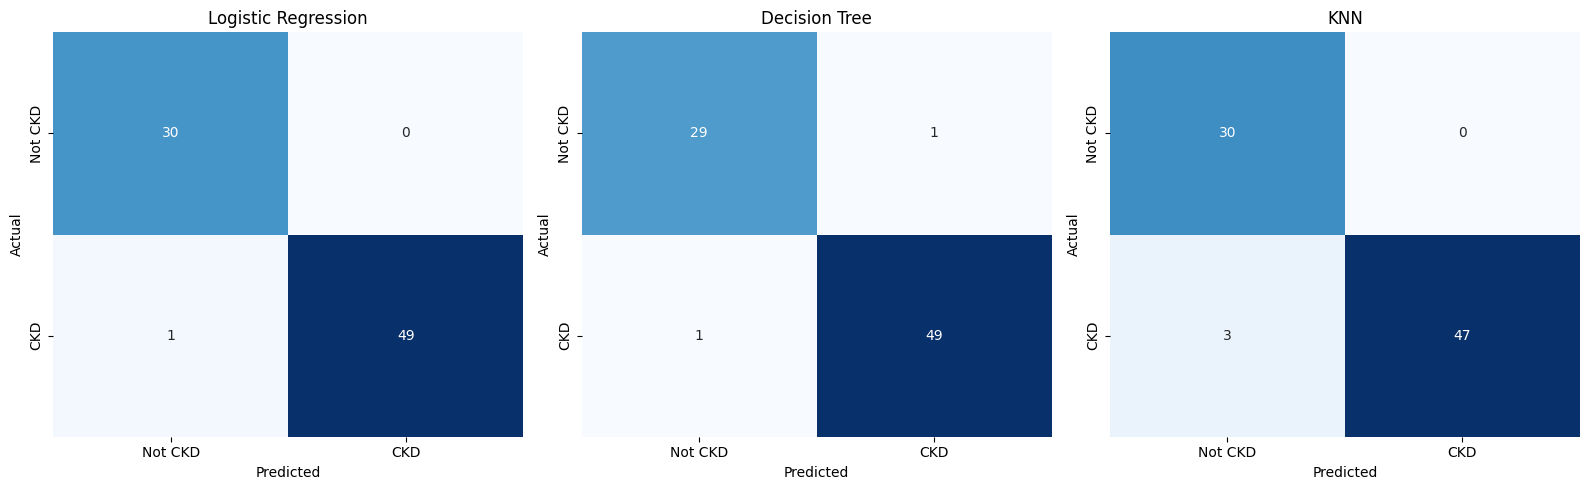

In [ ]:
# Confusion matrices for the base classifiers

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

base_predictions = [
    ("Logistic Regression", y_pred_logistic),
    ("Decision Tree", y_pred_tree),
    ("KNN", y_pred_knn)
]

for ax, (name, predictions) in zip(axes, base_predictions):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        cbar=False,
        xticklabels=["Not CKD", "CKD"],
        yticklabels=["Not CKD", "CKD"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 5. Stacking Ensemble

Stacking combines the predictions of multiple base classifiers using a second-level model called a **meta-classifier**.

In this experiment, Logistic Regression, Decision Tree, and KNN are used as the base classifiers. Logistic Regression is used as the meta-classifier.

The base classifiers learn different decision patterns, while the meta-classifier learns how to combine their predictions to produce the final classification.

The `StackingClassifier` internally uses cross-validation to generate out-of-fold base-model predictions for training the meta-classifier. The final base estimators are then fitted on the complete training data.

Note: The feature preprocessing in this educational practical is performed manually before the ensemble estimators. For a stricter production-grade stacking evaluation, preprocessing should also be refitted separately within each internal stacking fold.

In [ ]:
# Define base estimators for stacking

stacking_estimators = [
    ("logistic", LogisticRegression(
        max_iter=1000,
        random_state=42
    )),
    ("tree", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
    )),
    ("knn", KNeighborsClassifier(
        n_neighbors=5
    ))
]

# Create stacking classifier

stacking_model = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    cv=3,
    stack_method="predict_proba",
    n_jobs=-1
)

print("Stacking Ensemble created successfully.")

Stacking Ensemble created successfully.


In [ ]:
# Train Stacking Ensemble

print("Training Stacking Ensemble...")

stacking_model.fit(X_train_final, y_train)

print("Stacking Ensemble trained successfully.")

Training Stacking Ensemble...
Stacking Ensemble trained successfully.


In [ ]:
# Stacking predictions

y_pred_stacking = stacking_model.predict(X_test_final)
prob_stacking = stacking_model.predict_proba(X_test_final)

print("Stacking predictions generated successfully.")

Stacking predictions generated successfully.


In [ ]:
# Evaluate Stacking Ensemble

stacking_result = evaluate_model(
    "Stacking",
    y_test,
    y_pred_stacking,
    prob_stacking
)

pd.DataFrame([stacking_result]).round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Stacking,1.0,1.0,1.0,1.0,0.035


## 6. AdaBoost Ensemble

AdaBoost stands for **Adaptive Boosting**. It combines a sequence of weak learners to form a stronger classifier.

After each learner is trained, greater emphasis is placed on the observations that were incorrectly classified by previous learners. The next learner therefore focuses more on difficult training examples.

A shallow Decision Tree is used as the base estimator because shallow trees act as weak learners and allow AdaBoost to progressively improve the overall classifier.

In [ ]:
# Create a shallow Decision Tree as the AdaBoost base estimator

ada_base = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

# Create AdaBoost classifier

adaboost_model = AdaBoostClassifier(
    estimator=ada_base,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

print("AdaBoost model created successfully.")

AdaBoost model created successfully.


In [ ]:
# Train AdaBoost

print("Training AdaBoost...")

adaboost_model.fit(X_train_final, y_train)

print("AdaBoost trained successfully.")

Training AdaBoost...
AdaBoost trained successfully.


In [ ]:
# AdaBoost predictions

y_pred_adaboost = adaboost_model.predict(X_test_final)
prob_adaboost = adaboost_model.predict_proba(X_test_final)

print("AdaBoost predictions generated successfully.")

AdaBoost predictions generated successfully.


In [ ]:
# Evaluate AdaBoost

adaboost_result = evaluate_model(
    "AdaBoost",
    y_test,
    y_pred_adaboost,
    prob_adaboost
)

pd.DataFrame([adaboost_result]).round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,AdaBoost,0.9875,1.0,0.98,0.9899,0.251


## 7. Voting Ensemble

Voting combines predictions from multiple base classifiers to determine the final class.

For this practical, **Hard Voting** is used because the assignment specifically requires combining predictions through majority voting.

The three base classifiers are Logistic Regression, Decision Tree, and KNN. Each classifier casts one vote, and the class receiving the majority of votes is selected as the final prediction.

For example, if the three classifiers predict `CKD`, `Not CKD`, and `CKD`, the final majority-vote prediction is `CKD`.

In [ ]:
# Define fresh base estimators for Voting

voting_estimators = [
    ("logistic", LogisticRegression(
        max_iter=1000,
        random_state=42
    )),
    ("tree", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
    )),
    ("knn", KNeighborsClassifier(
        n_neighbors=5
    ))
]

# Create Hard Voting classifier

voting_model = VotingClassifier(
    estimators=voting_estimators,
    voting="hard",
    n_jobs=-1
)

print("Hard Voting Ensemble created successfully.")

Hard Voting Ensemble created successfully.


In [ ]:
# Train Voting Ensemble

print("Training Voting Ensemble...")

voting_model.fit(X_train_final, y_train)

print("Voting Ensemble trained successfully.")

Training Voting Ensemble...
Voting Ensemble trained successfully.


In [ ]:
# Voting predictions

y_pred_voting = voting_model.predict(X_test_final)

print("Voting predictions generated successfully.")

Voting predictions generated successfully.


In [ ]:
# Evaluate Hard Voting

voting_result = {
    "Model": "Voting",
    "Accuracy": accuracy_score(y_test, y_pred_voting),
    "Precision": precision_score(
        y_test, y_pred_voting,
        pos_label=1, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_voting,
        pos_label=1, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred_voting,
        pos_label=1, zero_division=0
    ),
    # Hard voting returns class labels, not probabilities.
    "Log Loss": np.nan
}

pd.DataFrame([voting_result]).round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Voting,0.9875,1.0,0.98,0.9899,NaN


In [ ]:
# Combine base-model and ensemble results

all_results = base_results + [
    stacking_result,
    adaboost_result,
    voting_result
]

results_df = pd.DataFrame(all_results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Logistic Regression,0.9875,1.00,0.98,0.9899,0.0395
1,Decision Tree,0.9750,0.98,0.98,0.9800,0.4739
2,KNN,0.9625,1.00,0.94,0.9691,0.0743
3,Stacking,1.0000,1.00,1.00,1.0000,0.0350
4,AdaBoost,0.9875,1.00,0.98,0.9899,0.2510
5,Voting,0.9875,1.00,0.98,0.9899,NaN


## 8. Comparative Performance Analysis

In [ ]:
# Display final comparison of all base and ensemble models

comparison_df = results_df.copy()

comparison_df = comparison_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Log Loss"
    ]
]

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Logistic Regression,0.9875,1.00,0.98,0.9899,0.0395
1,Decision Tree,0.9750,0.98,0.98,0.9800,0.4739
2,KNN,0.9625,1.00,0.94,0.9691,0.0743
3,Stacking,1.0000,1.00,1.00,1.0000,0.0350
4,AdaBoost,0.9875,1.00,0.98,0.9899,0.2510
5,Voting,0.9875,1.00,0.98,0.9899,NaN


In [ ]:
# Identify the best-performing model for each metric

print("Best Accuracy:",
      results_df.loc[results_df["Accuracy"].idxmax(), "Model"])

print("Best Precision:",
      results_df.loc[results_df["Precision"].idxmax(), "Model"])

print("Best Recall:",
      results_df.loc[results_df["Recall"].idxmax(), "Model"])

print("Best F1-Score:",
      results_df.loc[results_df["F1-Score"].idxmax(), "Model"])

Best Accuracy: Stacking
Best Precision: Logistic Regression
Best Recall: Stacking
Best F1-Score: Stacking


## 9. Performance Comparison Visualisation

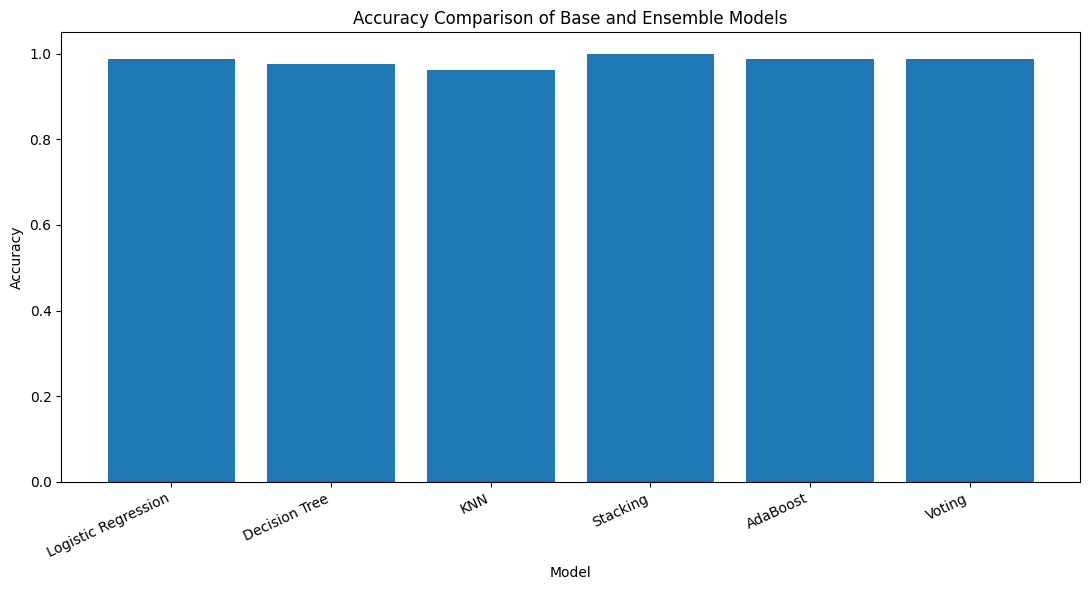

In [ ]:
# Accuracy comparison

plt.figure(figsize=(11, 6))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Accuracy Comparison of Base and Ensemble Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

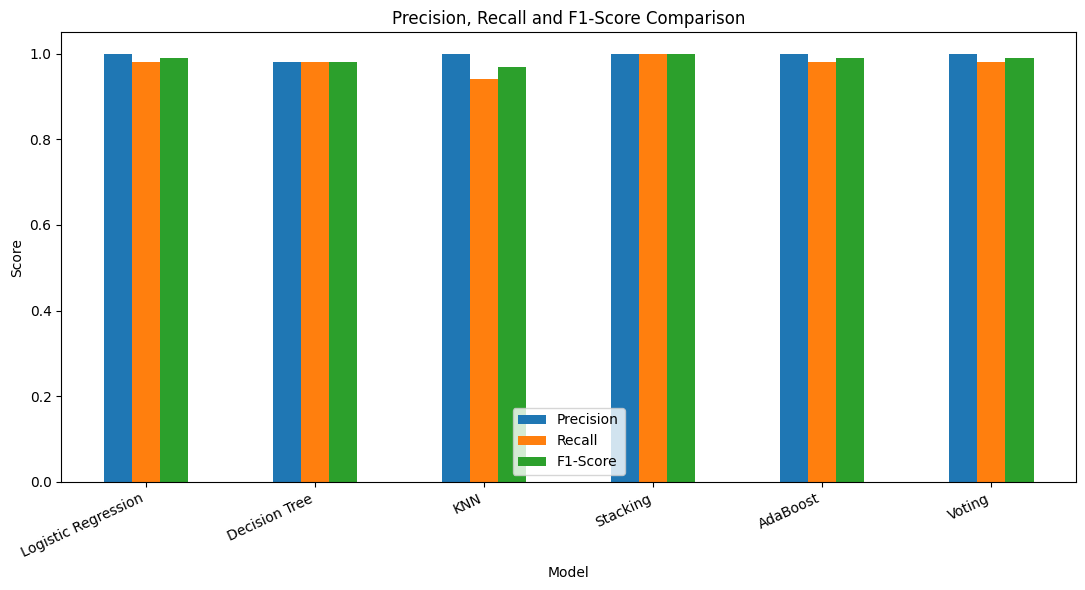

In [ ]:
# Compare Precision, Recall and F1-Score

metrics = ["Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Precision, Recall and F1-Score Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

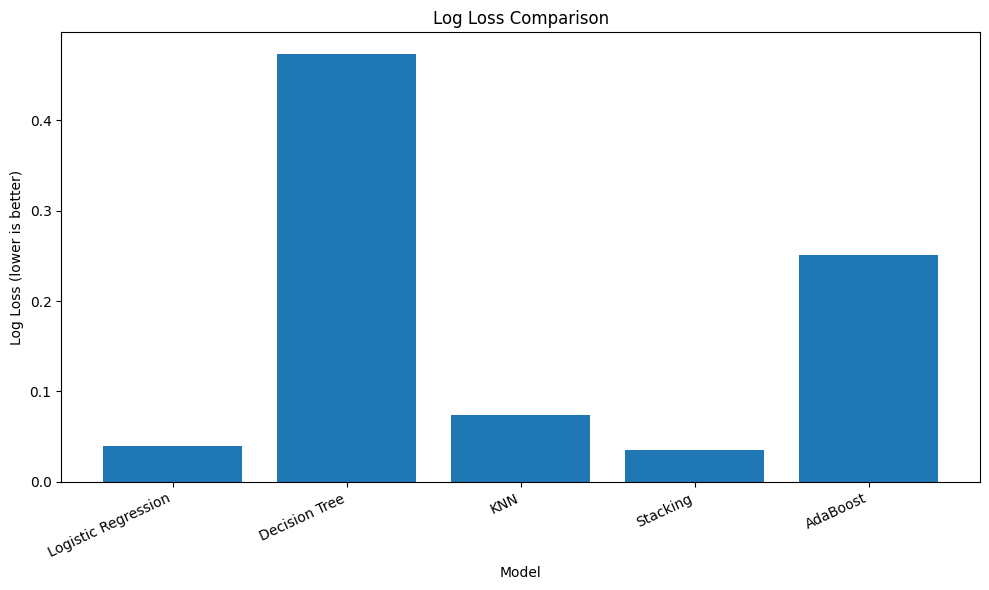

In [ ]:
# Log Loss comparison for models that provide probabilities

loss_df = results_df.dropna(subset=["Log Loss"])

plt.figure(figsize=(10, 6))

plt.bar(
    loss_df["Model"],
    loss_df["Log Loss"]
)

plt.title("Log Loss Comparison")
plt.xlabel("Model")
plt.ylabel("Log Loss (lower is better)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

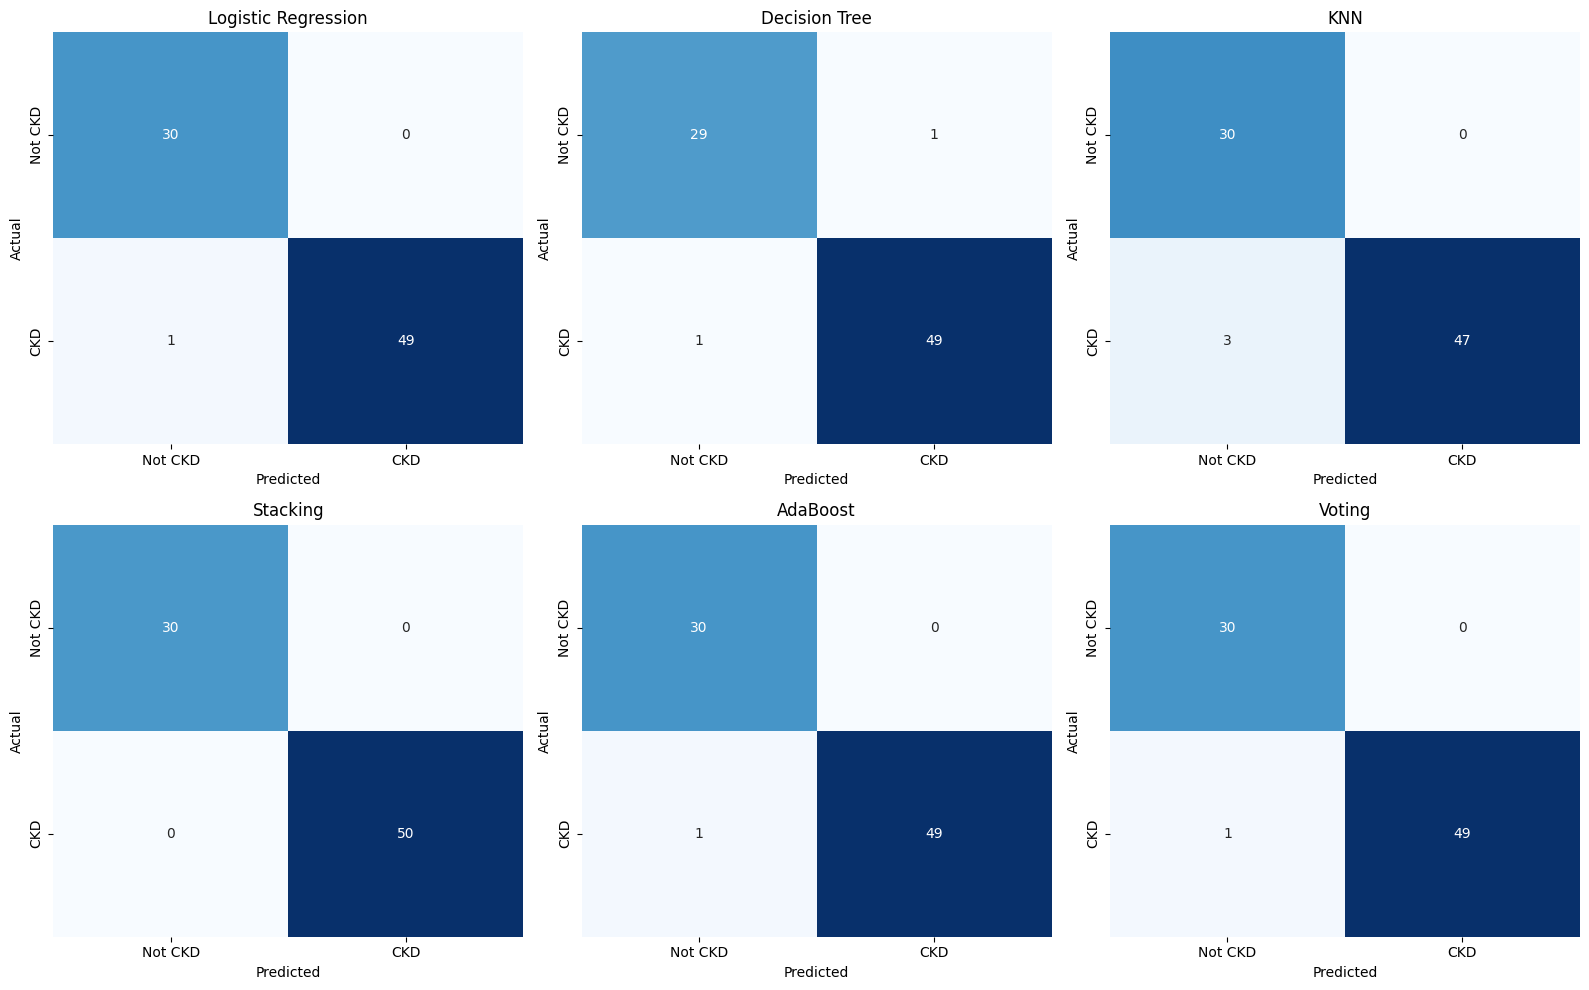

In [ ]:
# Confusion matrices for all models

all_predictions = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "KNN": y_pred_knn,
    "Stacking": y_pred_stacking,
    "AdaBoost": y_pred_adaboost,
    "Voting": y_pred_voting
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (model_name, predictions) in zip(
    axes.ravel(),
    all_predictions.items()
):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        cbar=False,
        xticklabels=["Not CKD", "CKD"],
        yticklabels=["Not CKD", "CKD"]
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 10. Base Classifier Diversity Analysis

In [ ]:
# Analyse prediction diversity among the base classifiers

base_prediction_df = pd.DataFrame({
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "KNN": y_pred_knn
})

# Percentage of test samples where pairs of classifiers disagree

lr_tree_disagreement = (
    base_prediction_df["Logistic Regression"] !=
    base_prediction_df["Decision Tree"]
).mean() * 100

lr_knn_disagreement = (
    base_prediction_df["Logistic Regression"] !=
    base_prediction_df["KNN"]
).mean() * 100

tree_knn_disagreement = (
    base_prediction_df["Decision Tree"] !=
    base_prediction_df["KNN"]
).mean() * 100

print(f"Logistic Regression vs Decision Tree disagreement: {lr_tree_disagreement:.2f}%")
print(f"Logistic Regression vs KNN disagreement: {lr_knn_disagreement:.2f}%")
print(f"Decision Tree vs KNN disagreement: {tree_knn_disagreement:.2f}%")

Logistic Regression vs Decision Tree disagreement: 3.75%
Logistic Regression vs KNN disagreement: 2.50%
Decision Tree vs KNN disagreement: 6.25%


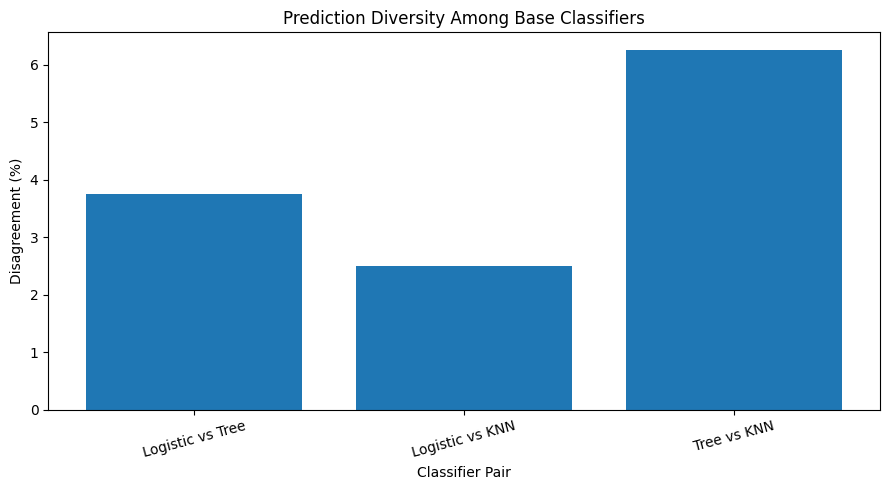

In [ ]:
# Visualize pairwise disagreement among base classifiers

diversity_data = pd.DataFrame({
    "Classifier Pair": [
        "Logistic vs Tree",
        "Logistic vs KNN",
        "Tree vs KNN"
    ],
    "Disagreement (%)": [
        lr_tree_disagreement,
        lr_knn_disagreement,
        tree_knn_disagreement
    ]
})

plt.figure(figsize=(9, 5))

plt.bar(
    diversity_data["Classifier Pair"],
    diversity_data["Disagreement (%)"]
)

plt.title("Prediction Diversity Among Base Classifiers")
plt.xlabel("Classifier Pair")
plt.ylabel("Disagreement (%)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

## 11. Critical Analysis of Results

The experimental results compare the individual base classifiers—Logistic Regression, Decision Tree, and KNN—with three ensemble methods: Stacking, AdaBoost, and Hard Voting.

Use the generated comparison table and confusion matrices to determine which model performed best. The analysis should consider:

- **Accuracy:** Overall proportion of correctly classified patient records.
- **Precision (CKD):** Among records predicted as CKD, the proportion that are actually CKD.
- **Recall (CKD):** Among actual CKD records, the proportion identified by the model.
- **F1-Score (CKD):** Harmonic mean of CKD precision and recall.
- **Log Loss:** Quality of predicted probabilities; lower values are better.

**Stacking** may benefit when the base classifiers make complementary predictions because the meta-classifier learns how to combine their outputs.

**AdaBoost** trains weak learners sequentially and places greater emphasis on observations misclassified by previous learners. It can be useful when the weak learners can progressively improve, but may be sensitive to noisy or mislabeled records.

**Hard Voting** combines class predictions using majority voting. It is straightforward, but it does not learn a separate meta-classifier.

The diversity analysis measures how often pairs of base classifiers disagree. Different predictions can indicate that classifiers have complementary behaviour, although disagreement alone does not guarantee a better ensemble.

In [ ]:
# Compare false negatives and false positives for all models

error_rows = []

for model_name, predictions in all_predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    error_rows.append({
        "Model": model_name,
        "True Negative": tn,
        "False Positive": fp,
        "False Negative": fn,
        "True Positive": tp
    })

error_comparison = pd.DataFrame(error_rows).set_index("Model")
display(error_comparison)

,True Negative,False Positive,False Negative,True Positive
Model,,,,
Logistic Regression,30,0,1,49
Decision Tree,29,1,1,49
KNN,30,0,3,47
Stacking,30,0,0,50
AdaBoost,30,0,1,49
Voting,30,0,1,49


## 12. Strengths and Limitations of Ensemble Methods

### Stacking

**Strengths:**
- Combines different types of classifiers.
- A meta-classifier learns how to combine base-model predictions.
- Can exploit complementary strengths of diverse models.

**Limitations:**
- More computationally expensive than a single classifier.
- More complex to implement and tune.
- Performance depends on the quality and diversity of base classifiers.

### AdaBoost

**Strengths:**
- Can combine several weak learners into a stronger classifier.
- Focuses sequentially on difficult training observations.
- Often improves the performance of a weak base learner.

**Limitations:**
- Can be sensitive to noisy or incorrectly labelled data.
- Learners are trained sequentially, so training is less parallelisable.
- Performance depends on the base estimator and boosting parameters.

### Voting

**Strengths:**
- Simple and easy to interpret.
- Combines predictions from multiple classifiers.
- Majority voting can reduce the effect of an individual model's errors.

**Limitations:**
- Hard voting does not learn an explicit meta-model.
- Performance depends on base classifier quality and diversity.
- A group of weak or highly similar classifiers may provide limited benefit.

## 13. Suitability and Applications

| Ensemble Method | Best Suited For | Main Advantage | Main Concern |
|---|---|---|---|
| **Stacking** | Problems where different classifiers have complementary strengths | Learns how to combine base predictions | Higher complexity |
| **AdaBoost** | Problems where weak learners can be improved sequentially | Focuses on difficult observations | Sensitive to noisy data |
| **Voting** | Situations requiring a simple combination of multiple classifiers | Simple and interpretable | Does not learn complex combinations |

For the CKD classification task, model selection should consider recall and false-negative counts for the CKD class, in addition to overall accuracy. The output of this educational notebook must not be used as a clinical diagnosis.

## 14. Future Scope and Improvements

Several improvements can be explored in future work:

1. **Hyperparameter Optimisation:** Grid Search or Randomized Search can be used to optimise the parameters of base classifiers and ensemble models.
2. **Larger Dataset:** The experiment can be repeated using larger and independent CKD datasets to evaluate generalisation.
3. **More Diverse Base Models:** Additional classifiers such as SVM, Random Forest, Gradient Boosting, or other algorithms can be incorporated to increase model diversity.
4. **Feature Selection:** Relevant clinical attributes can be selected to reduce unnecessary features and improve interpretability.
5. **Ensemble Weight Optimisation:** Voting weights can be tuned rather than treating every classifier equally.
6. **Threshold Optimisation:** Classification thresholds can be selected according to the relative importance of false negatives and false positives.
7. **External Validation:** Models should be tested on independent clinical datasets from different patient populations and settings.
8. **Explainability and Calibration:** Feature explanation and probability calibration can be explored before any clinical research use.

The dataset contains only 400 records, so results should be interpreted cautiously. More data and external validation would be necessary before considering real-world clinical applications.

## 15. Conclusion

In this practical, three ensemble learning techniques—Stacking, AdaBoost, and Hard Voting—were implemented for Chronic Kidney Disease classification using the UCI CKD dataset. Logistic Regression, Decision Tree, and K-Nearest Neighbours were used as the base classifiers. The data was prepared through manual preprocessing, including missing-value imputation, categorical encoding, age-group creation, log transformation, and feature scaling.

The performance of the individual base classifiers was compared with the three ensemble methods using accuracy, CKD precision, CKD recall, F1-score, log loss, and confusion matrices. Base-classifier diversity was also examined by measuring the percentage of predictions on which classifier pairs disagreed.

The experiment demonstrates that ensemble methods can combine different learning approaches, but their effectiveness depends on base-model quality, prediction diversity, data quality, and parameter selection. This notebook is an academic machine-learning exercise and is not a validated medical diagnostic system.